In [19]:
# Heart Disease Data Analysis and Prediction


import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style='whitegrid')

## 1. Load and first look

In [2]:
df = pd.read_csv('heart.csv')
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [4]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Duplicate rows: 0
Missing values: 0


<Axes: title={'center': 'Heart disease (1 = yes)'}, xlabel='HeartDisease'>

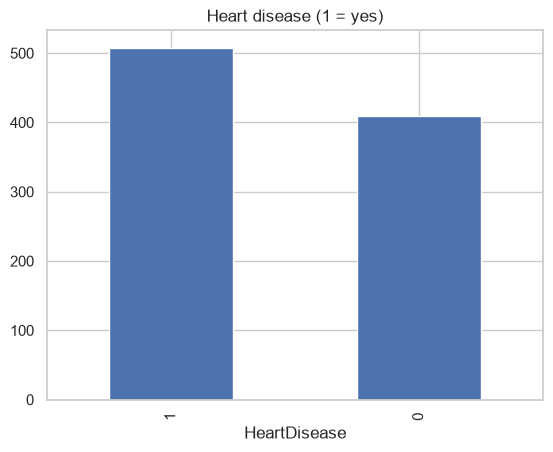

In [5]:
print('Duplicate rows:', df.duplicated().sum())
print('Missing values:', df.isnull().sum().sum())
df['HeartDisease'].value_counts().plot(kind='bar', title='Heart disease (1 = yes)')

## 2. The hidden data-quality problem
There are no `NaN` values, but `describe()` shows a minimum cholesterol of 0, which is not possible for a living person. Zeros are acting as missing values.

In [6]:
zero_chol = (df['Cholesterol'] == 0).sum()
zero_bp = (df['RestingBP'] == 0).sum()
print(f'Cholesterol = 0: {zero_chol} rows ({zero_chol / len(df):.1%})')
print(f'RestingBP = 0:   {zero_bp} row')

Cholesterol = 0: 172 rows (18.7%)
RestingBP = 0:   1 row


**Are these zeros random?** If the zero-cholesterol patients have a very different heart disease rate, the missingness itself carries information, and filling it with the mean would hide that.

Cholesterol
Cholesterol recorded    0.477
Cholesterol = 0         0.884
Name: HeartDisease, dtype: float64


(array([0, 1]),
 [Text(0, 0, 'Cholesterol recorded'), Text(1, 0, 'Cholesterol = 0')])

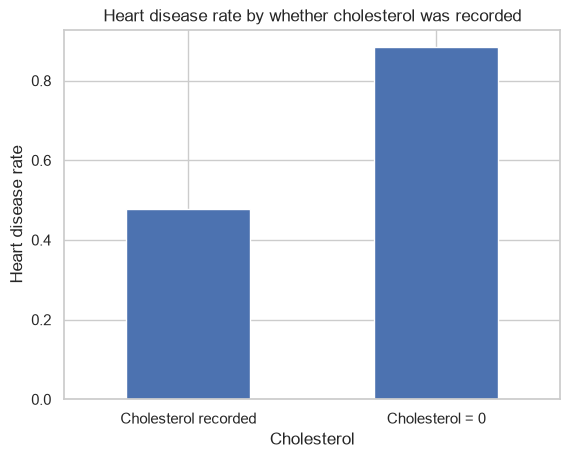

In [7]:
rate = df.groupby(df['Cholesterol'] == 0)['HeartDisease'].mean().rename({False: 'Cholesterol recorded', True: 'Cholesterol = 0'})
print(rate.round(3))
rate.plot(kind='bar', title='Heart disease rate by whether cholesterol was recorded')
plt.ylabel('Heart disease rate'); plt.xticks(rotation=0)

**Decision:** treat 0 as missing, add a `Cholesterol_missing` flag so the model can use that signal, and impute the actual values with the **median** later, inside the pipeline.

In [8]:
df_clean = df.copy()
df_clean['Cholesterol_missing'] = (df_clean['Cholesterol'] == 0).astype(int)
df_clean['Cholesterol'] = df_clean['Cholesterol'].replace(0, np.nan)
df_clean['RestingBP'] = df_clean['RestingBP'].replace(0, np.nan)
df_clean.isnull().sum()[lambda s: s > 0]

RestingBP        1
Cholesterol    172
dtype: int64

## 3. Exploratory data analysis

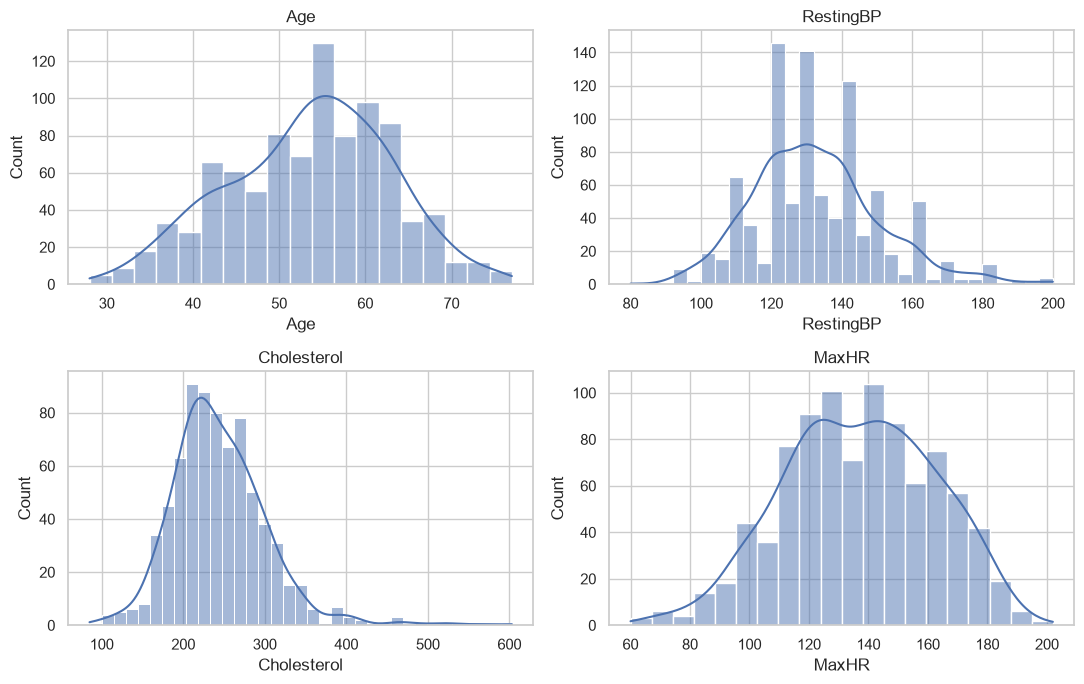

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()

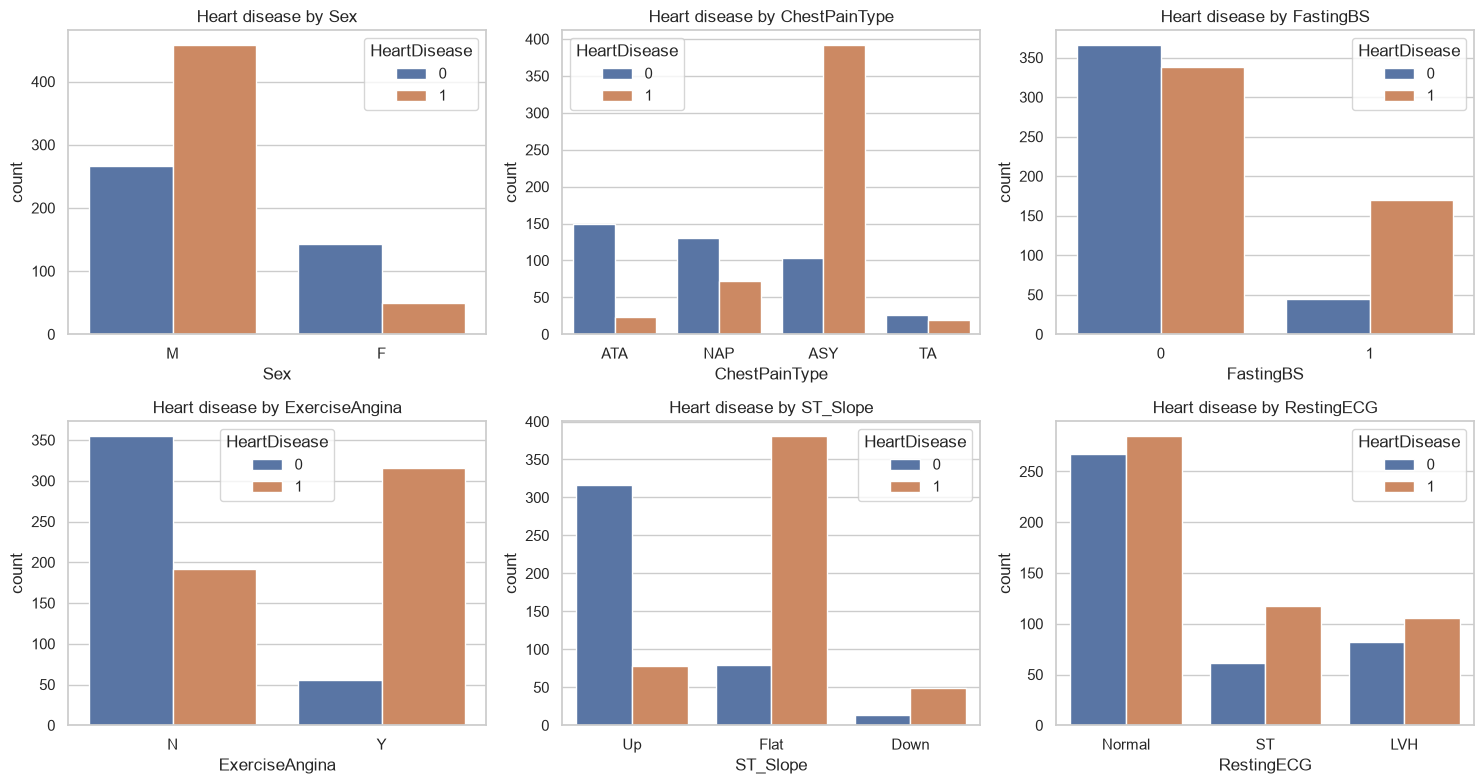

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ['Sex', 'ChestPainType', 'FastingBS', 'ExerciseAngina', 'ST_Slope', 'RestingECG']):
    sns.countplot(data=df_clean, x=col, hue='HeartDisease', ax=ax)
    ax.set_title(f'Heart disease by {col}')
plt.tight_layout()

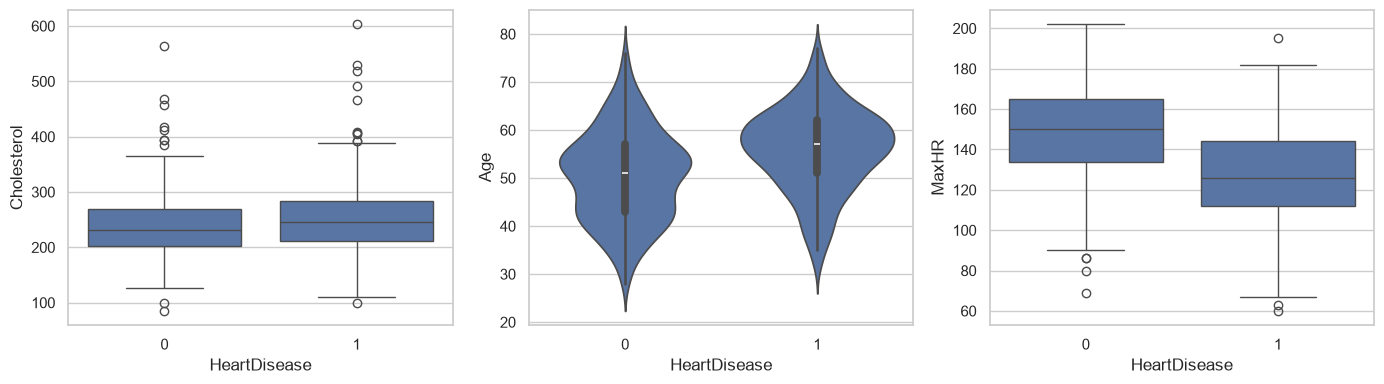

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(data=df_clean, x='HeartDisease', y='Cholesterol', ax=axes[0])
sns.violinplot(data=df_clean, x='HeartDisease', y='Age', ax=axes[1])
sns.boxplot(data=df_clean, x='HeartDisease', y='MaxHR', ax=axes[2])
plt.tight_layout()

<Axes: >

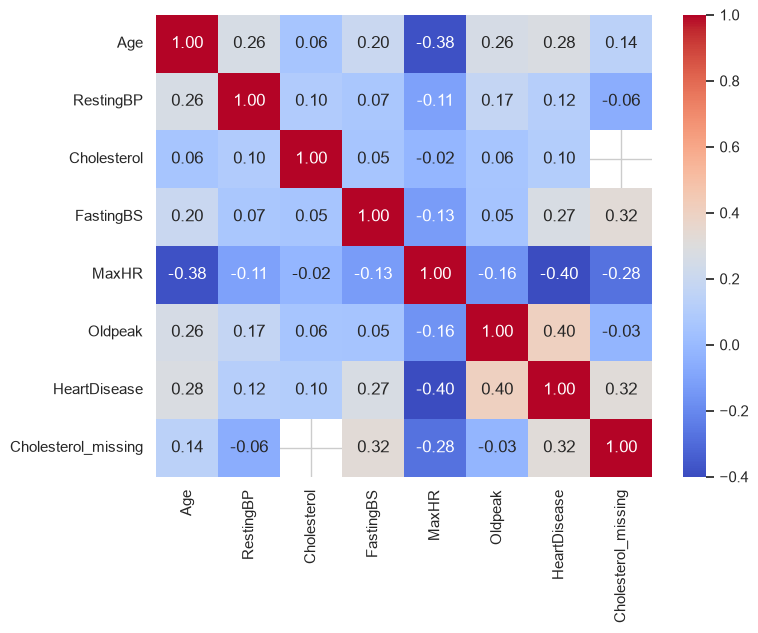

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')

## 4. Feature engineering

In [13]:
df_clean['HighBP'] = (df_clean['RestingBP'] >= 140).astype(int)
df_clean['HighCholesterol'] = (df_clean['Cholesterol'] >= 240).astype(int)
df_clean['AgeGroup'] = pd.cut(df_clean['Age'], bins=[0, 40, 55, 70, 100],
                              labels=['Young', 'Middle', 'Senior', 'Old']).astype(str)
df_clean['RiskScore'] = df_clean['HighBP'] + df_clean['HighCholesterol'] + df_clean['FastingBS']

print(df_clean.groupby('RiskScore')['HeartDisease'].agg(['mean', 'count']).round(3))
print()
print(df_clean.groupby('AgeGroup')['HeartDisease'].agg(['mean', 'count']).round(3))

            mean  count
RiskScore              
0          0.439    278
1          0.562    409
2          0.667    198
3          0.727     33

           mean  count
AgeGroup              
Middle    0.451    419
Old       0.667     24
Senior    0.709    382
Young     0.344     93


## 5. Modelling
Stratified split keeps the disease/no-disease ratio the same in train and test. Imputation, scaling and encoding are fitted on the training set only.

In [14]:
X = df_clean.drop(columns='HeartDisease')
y = df_clean['HeartDisease']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
bin_cols = ['FastingBS', 'HighBP', 'HighCholesterol', 'RiskScore', 'Cholesterol_missing']
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'AgeGroup']

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('bin', 'passthrough', bin_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

models = {
    'Logistic Regression': Pipeline([('prep', preprocess), ('model', LogisticRegression(max_iter=1000))]),
    'Random Forest': Pipeline([('prep', preprocess), ('model', RandomForestClassifier(n_estimators=200, random_state=42))]),
}

rows, fitted = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = (pipe, pred)
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, proba)})

results = pd.DataFrame(rows).round(3)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.891,0.902,0.902,0.902,0.932
1,Random Forest,0.897,0.895,0.922,0.908,0.937


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, pipe in models.items():
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='roc_auc')
    print(f'{name}: 5-fold ROC-AUC = {scores.mean():.3f} (+/- {scores.std():.3f})')

Logistic Regression: 5-fold ROC-AUC = 0.928 (+/- 0.016)
Random Forest: 5-fold ROC-AUC = 0.924 (+/- 0.022)


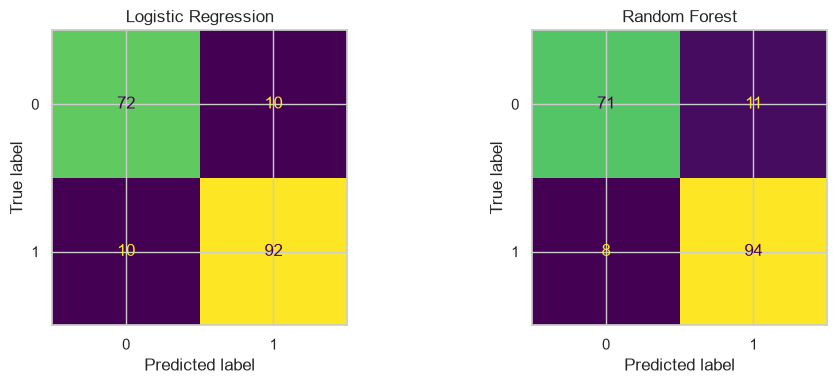

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, (pipe, pred)) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()

Text(0.5, 1.0, 'Top 10 features (Random Forest)')

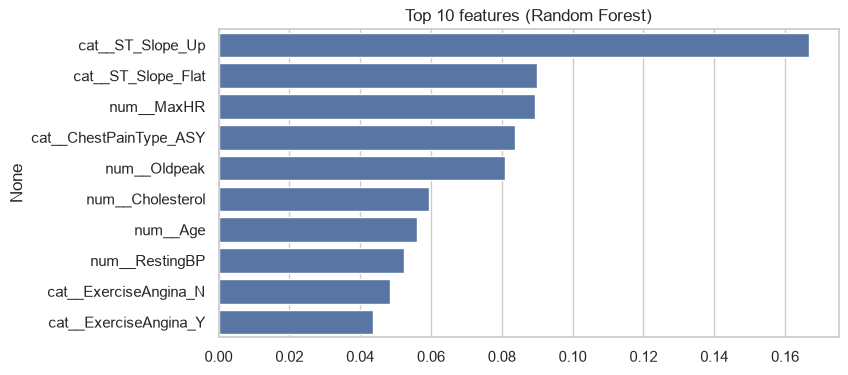

In [17]:
rf = fitted['Random Forest'][0]
names = rf[:-1].get_feature_names_out()
imp = pd.Series(rf[-1].feature_importances_, index=names).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4))
sns.barplot(x=imp.values, y=imp.index)
plt.title('Top 10 features (Random Forest)')

## 6. Findings (generated from the results above)

In [18]:
from IPython.display import Markdown
best = results.sort_values('ROC-AUC', ascending=False).iloc[0]
Markdown(f'''
- **{zero_chol} of {len(df)} records ({zero_chol / len(df):.1%})** had an impossible cholesterol of 0.
- Those patients had a heart disease rate of **{rate['Cholesterol = 0']:.0%}**, versus **{rate['Cholesterol recorded']:.0%}** for patients with a recorded value, so missingness was informative. This is why a missing-value flag was added instead of only using the mean.
- Best model: **{best['Model']}** with accuracy {best['Accuracy']:.2f}, recall {best['Recall']:.2f}, and ROC-AUC {best['ROC-AUC']:.2f} on the test set.
- Both models score similarly (about 0.93 ROC-AUC in cross-validation), so the simpler, easier-to-explain logistic regression is a reasonable choice.
- Recall matters most here because missing a sick patient is worse than a false alarm.
- Top predictors: **{', '.join(imp.index[:3])}**.
- Limitation: only 918 patients, so results can vary; this is a learning project, not a medical tool.
''')


- **172 of 918 records (18.7%)** had an impossible cholesterol of 0.
- Those patients had a heart disease rate of **88%**, versus **48%** for patients with a recorded value, so missingness was informative. This is why a missing-value flag was added instead of only using the mean.
- Best model: **Random Forest** with accuracy 0.90, recall 0.92, and ROC-AUC 0.94 on the test set.
- Both models score similarly (about 0.93 ROC-AUC in cross-validation), so the simpler, easier-to-explain logistic regression is a reasonable choice.
- Recall matters most here because missing a sick patient is worse than a false alarm.
- Top predictors: **cat__ST_Slope_Up, cat__ST_Slope_Flat, num__MaxHR**.
- Limitation: only 918 patients, so results can vary; this is a learning project, not a medical tool.
